# FL-SEC-001.3 — Secure aggregation with dropout recovery

*Epic EPIC-001 · story fl_sec_001 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Implement Bonawitz-style secure aggregation (X25519, HKDF, ChaCha20-Poly1305, Shamir, double masking) with dropout recovery and security checks.

## 2. Scientific background
Pairwise masks cancel in the sum; Shamir shares of seeds allow recovery when clients drop [bonawitz2017]; sparse neighbour graphs reduce cost [bell2020].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Is the aggregate exact under dropout?
- **RQ2.** What does the server view look like, and when does the protocol abort?

## 4. Hypotheses
- **H1.** Aggregate error < 1e-6 with ≤ (1−threshold) dropout.
- **H2.** Server view is statistically unrelated to plaintext.

## 5. Mathematical formulation
y_i = x_i + PRG(b_i) + Σ_{j>i} PRG(s_ij) − Σ_{j<i} PRG(s_ij) (mod 2^64); Σ y_i − Σ b-masks = Σ x_i; Shamir over GF(2^521−1) with threshold t.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_sec_001"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_sec_001


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "P": 1442,
 "n": 10,
 "parties": [
  2,
  3,
  5
 ],
 "clients": [
  5,
  10,
  20
 ]
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`crypto/secagg.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.privacy.secure_aggregation import SecureAggregationProtocol, SecAggAbort
n, P = 10, 64; r = np.random.default_rng(SEED); D = r.normal(0, .1, (n, P)); W = r.integers(5, 50, n).astype(float)
pr = SecureAggregationProtocol(n, P)
out, w = pr.run({i: D[i] for i in range(n)}, {i: W[i] for i in range(n)}, drop_before_unmask={2, 3})
print("dropout (2 clients after masking) -> max error vs plaintext:", float(np.abs(out - (W / W.sum()) @ D).max())); assert np.abs(out - (W / W.sum()) @ D).max() < 1e-6
try:
    SecureAggregationProtocol(n, P).run({i: D[i] for i in range(n)}, {i: W[i] for i in range(n)}, drop_before_masking=set(range(7)))
except SecAggAbort as e: print("abort below threshold:", e)

dropout (2 clients after masking) -> max error vs plaintext: 1.886341499668376e-09
abort below threshold: client 0: only 3 shares available, need 7


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-SEC-001.3` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_1_3_cost_vs_clients.csv')
show_csv('task_1_3_dropout.csv')

,n,graph,total_s,up_kb_per_client,plaintext_kb_per_client,comm_overhead_x,max_abs_err,phase_r1_s,phase_r2_s,phase_r4_s,threshold_mean
0,5,complete,0.0151,12.3242,5.6328,2.1879,0.0,0.0032,0.0042,0.0003,4.0
1,10,complete,0.0255,13.4766,5.6328,2.3925,0.0,0.0058,0.0179,0.0008,7.0
2,20,complete,0.1030,15.7812,5.6328,2.8017,0.0,0.0302,0.0664,0.0044,14.0
3,20,sparse k=14,0.0724,14.6289,5.6328,2.5971,0.0,0.0175,0.0496,0.0032,11.0
4,50,complete,0.7268,22.6953,5.6328,4.0291,0.0,0.1990,0.4511,0.0694,34.0
5,50,sparse k=14,0.2374,14.6289,5.6328,2.5971,0.0,0.0677,0.1530,0.0098,11.0
6,100,complete,3.4974,34.2188,5.6328,6.0749,0.0,1.0399,1.8665,0.5777,67.0
7,100,sparse k=14,0.4600,14.6289,5.6328,2.5971,0.0,0.1501,0.2730,0.0233,11.0


,stage,drop_fraction,trials,completed,aborted,max_abs_err,threshold_frac,n
0,before_masking,0.0,5,5,0,0.0,0.67,20
1,before_masking,0.1,5,5,0,0.0,0.67,20
2,before_masking,0.2,5,5,0,0.0,0.67,20
3,before_masking,0.3,5,5,0,0.0,0.67,20
4,before_masking,0.4,5,0,5,NaN,0.67,20
5,before_unmask,0.0,5,5,0,0.0,0.67,20
6,before_unmask,0.1,5,5,0,0.0,0.67,20
7,before_unmask,0.2,5,5,0,0.0,0.67,20
8,before_unmask,0.3,5,5,0,0.0,0.67,20
9,before_unmask,0.4,5,0,5,NaN,0.67,20


## 12. Metrics collection
Metric definitions: MEASURED: aggregate error, round time, bytes; security checks are protocol-level assertions, not a security proof.

In [8]:
show_csv('task_1_3_dropout.csv')

,stage,drop_fraction,trials,completed,aborted,max_abs_err,threshold_frac,n
0,before_masking,0.0,5,5,0,0.0,0.67,20
1,before_masking,0.1,5,5,0,0.0,0.67,20
2,before_masking,0.2,5,5,0,0.0,0.67,20
3,before_masking,0.3,5,5,0,0.0,0.67,20
4,before_masking,0.4,5,0,5,NaN,0.67,20
5,before_unmask,0.0,5,5,0,0.0,0.67,20
6,before_unmask,0.1,5,5,0,0.0,0.67,20
7,before_unmask,0.2,5,5,0,0.0,0.67,20
8,before_unmask,0.3,5,5,0,0.0,0.67,20
9,before_unmask,0.4,5,0,5,NaN,0.67,20


## 13. Statistical analysis
Deterministic correctness checks; costs reported per client count.

In [9]:
J = json.load(open(RES / 'task_1_3_security_checks.json')); print(json.dumps(J, indent=1))

{
 "server_view_corr_with_plain": 0.029548298169683455,
 "server_view_high_bit_fraction": 0.48440748440748443,
 "shamir_t_shares_recover": true,
 "shamir_t_minus_1_shares_recover": false,
 "abort_below_threshold": "aborted as designed: client 0: only 3 shares available, need 7",
 "tampered_share_detected": true,
 "flower_version": "1.43.0",
 "flower_secaggplus_mod_present": true,
 "flower_end_to_end_run": "NOT_RUN (requires SuperLink/SuperNode runtime; this protocol is a from-scratch implementation of the same design)",
 "fl_integration": {
  "final_acc": 0.7644444444444445,
  "max_agg_error": 3.725290298461914e-09,
  "rounds": 8
 }
}


## 14. Visualizations

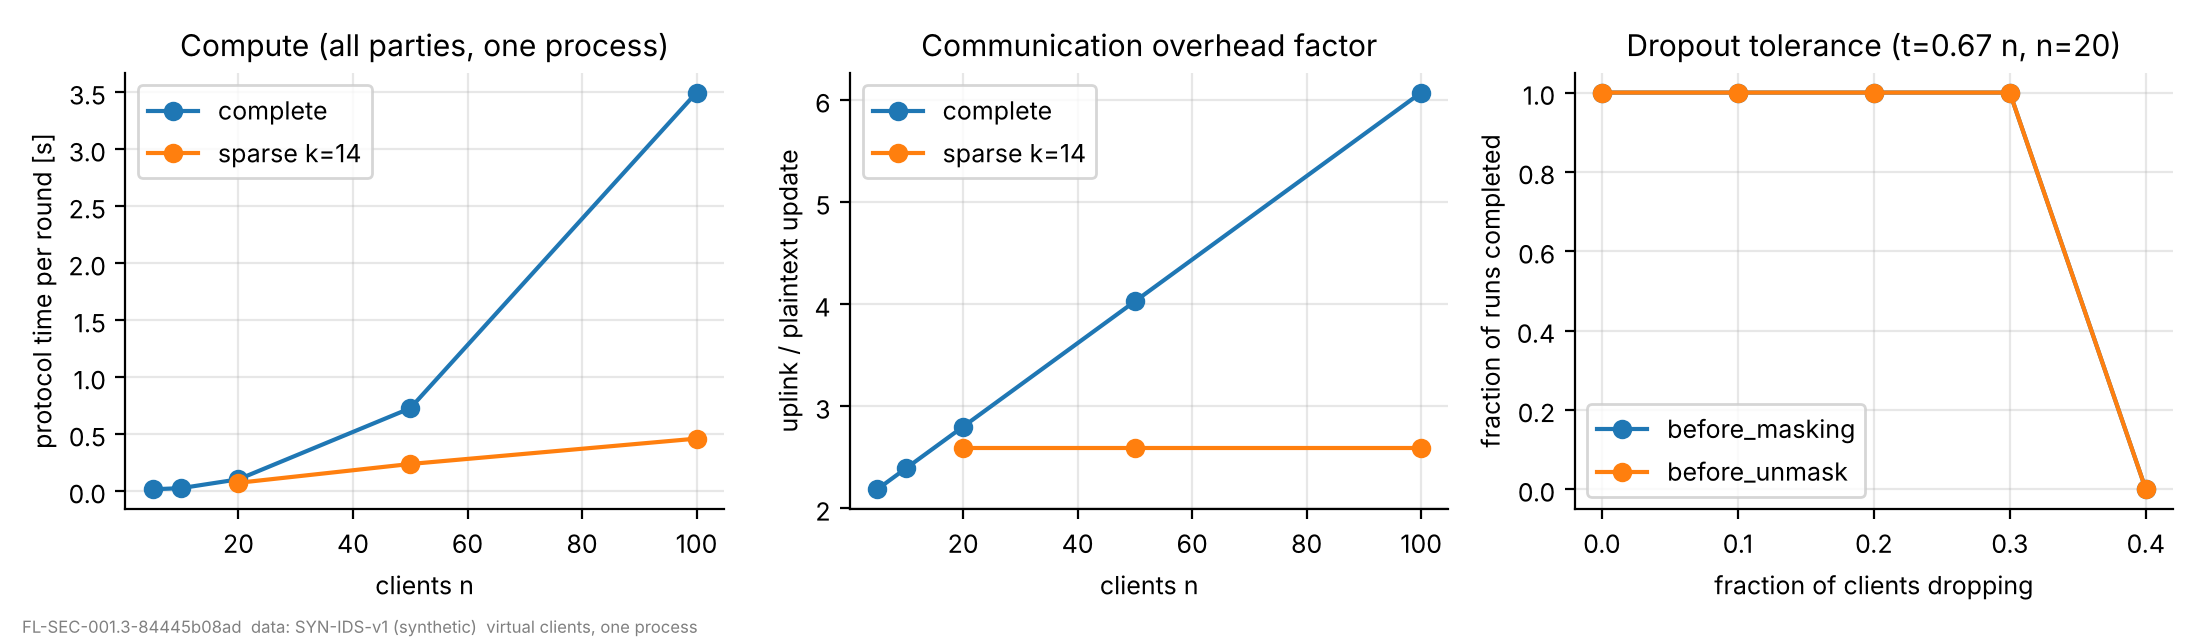

In [10]:
show_fig('task_1_3_secagg.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Correctness under dropout, abort below threshold and tamper detection are demonstrated; a consistency/signature round (needed against a malicious server) is NOT implemented.

In [11]:
J = json.load(open(RES / 'task_1_3_security_checks.json')); print({k: J[k] for k in ['server_view_corr_with_plain','shamir_t_shares_recover','shamir_t_minus_1_shares_recover','abort_below_threshold','tampered_share_detected','flower_end_to_end_run']})

{'server_view_corr_with_plain': 0.029548298169683455, 'shamir_t_shares_recover': True, 'shamir_t_minus_1_shares_recover': False, 'abort_below_threshold': 'aborted as designed: client 0: only 3 shares available, need 7', 'tampered_share_detected': True, 'flower_end_to_end_run': 'NOT_RUN (requires SuperLink/SuperNode runtime; this protocol is a from-scratch implementation of the same design)'}


## 16. Limitations
- Semi-honest server only.
- Flower's secaggplus primitives were inspected but not run end-to-end (NOT_RUN).
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Secure aggregation with dropout recovery works in simulation and is exact to quantisation precision.

**Jira acceptance:** see `docs/fl_sec_001/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`bonawitz2017`, `bell2020`, `shamir1979` — details in `docs/fl_sec_001/references.md`.